# Helsinki region: typical trips to daily-life destinations, by user and by postal code

How far, how long and how much CO₂ does a resident of each postal code travel to
reach the places they actually visit, per type of destination?

The notebook reuses the carbon-budget paper's results at H3 resolution 9 (stays
of app users over March to May 2024 and the public transport, car and bicycle
origin-destination matrices, plus an e-bike derived from the bicycle matrix) and
reproduces the per-user "typical trip" curves of
that paper, now with distance and time beside CO₂, before summarising them per
postal code.

**Logic, in one paragraph.** A user's stays outside home and work are matched
with the number of POIs of each category in the stay hexagon. For one category,
every stay enters the user's curve with weight `visit frequency × POI count`.
Sorting the stays by the cost of the round trip from home gives the cumulative
share of the user's visits reached within a given cost; the cost at a share of
50 % is the user's typical trip for that category, and the other deciles describe
the shape of the curve. Per postal code, these per-user values are summarised
across residents (median, mean, quartiles), so every resident counts once.

**Inputs** (all pre-existing)

- `users_and_stays_3months.parquet`: user × stay hexagon, visits in the period,
  home and work hexagon (carbon-budget notebook 9.1).
- `pois_per_hex_new_class.parquet`: POIs per hexagon and category (notebook 1.x).
- `Postinumeroalueet_2024.shp`: the 172 postal code areas of Helsinki, Espoo and
  Vantaa.
- Mode matrices on scratch: `pt_co2_3000_1`, `car_co2_6000`, `bike_co2_3000`.
- `pt_typ_cat`, `car_typ_cat`, `bike_typ_cat` on scratch: the paper's per-user
  tables, read only by the reproduction check.

**Outputs** on scratch under `carbon-advantage/helsinki/visitation/`

- `typical_trip_by_user.parquet`: one row per user, category, mode and currency,
  with the cost at every decile of the user's visits.
- `typical_trip_by_postal_code.parquet`: one row per postal code (with its
  municipality), category, mode, currency and decile, with the median, mean and
  quartiles across residents.
- `typical_trip_thresholds.parquet`: one row per postal code, category, mode and
  currency, with the median across residents of the cost at 20, 25, 50 and 75 %
  of visits; `typical_trip_thresholds_<currency>.csv` holds the same in wide form.
- `parameters.json`: the settings below.

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import h3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.dataset as ds
from shapely.geometry import Polygon

## Parameters

Everything that could be argued about is set here. `WEIGHT_BY_FREQUENCY = False`
reproduces the definition of the carbon-budget paper's `*_typ_cat` tables, where a
stay counts once per POI regardless of how often it was visited.

In [2]:
PAPER = Path("/projappl/project_2010423/carbon_budgets_paper")
SCRATCH = Path("/scratch/project_2010423")
RESULTS = SCRATCH / "carbon-advantage" / "helsinki" / "visitation"
RESULTS.mkdir(parents=True, exist_ok=True)

STAYS = SCRATCH / "data" / "users_and_stays_3months.parquet"
POIS = PAPER / "data" / "pois_per_hex_new_class.parquet"
POSTAL_CODES = PAPER / "data" / "postal_code" / "Postinumeroalueet_2024.shp"
# The paper's per-user tables (notebook 9.4 and its bicycle and car versions),
# read only by the reproduction check in section 6.
PAPER_TABLES = {mode: SCRATCH / f"{mode}_typ_cat.parquet" for mode in ("pt", "car", "bike")}

# Destination categories of the carbon-budget paper ("Others / Not sure" left out).
CATEGORIES = [
    "Education",
    "Healthcare and Health",
    "Recreational, Outdoors",
    "Shopping, Errands",
    "Social, Cultural",
]

# One origin-destination matrix per mode: file, key columns and the cost columns
# renamed to common currency names. Times are minutes, distances metres, CO2 grams.
MATRICES = {
    "pt": dict(
        path=SCRATCH / "pt_co2_3000_1.parquet",
        origin="from_id", destination="to_id",
        costs={"pt_co2_total": "co2_g", "pt_dist": "distance_m", "pt_time": "time_min"},
    ),
    "car": dict(
        path=SCRATCH / "car_co2_6000.parquet",
        origin="Origin_Hexagon_ID", destination="Destination_Hexagon_ID",
        costs={"car_co2": "co2_g", "car_dist": "distance_m", "car_time": "time_min"},
    ),
    "bike": dict(
        path=SCRATCH / "bike_co2_3000.parquet",
        origin="from_id", destination="to_id",
        costs={"co2_emissions_g": "co2_g", "travel_distance": "distance_m"},
    ),
}
CURRENCIES = ["co2_g", "distance_m", "time_min"]

# Cumulative share of a user's visits (percent) at which the cost is read off: the
# paper's deciles plus the quartiles.
THRESHOLDS = sorted(set(range(0, 101, 10)) | {25, 75})
REPORTED_THRESHOLDS = [20, 25, 50, 75]  # shares shown in the postal-code table

# Display label and scale of each currency.
UNITS = {"co2_g": ("kg CO2e per round trip", 1 / 1000),
         "distance_m": ("km per round trip", 1 / 1000),
         "time_min": ("minutes per round trip", 1.0)}

WEIGHT_BY_FREQUENCY = True     # stay weight = visits x POI count (False: POI count only)
ROUND_TRIP = True              # cost = outbound + return leg, as in the paper
MIN_VISITS_PER_USER = 5        # weighted visits a user needs in a category
MIN_USERS_PER_POSTAL_CODE = 20 # residents a postal code needs to be reported
CYCLING_SPEED_KMPH = 15.3      # bicycle time = route distance / speed (the matrix has no time)
# The e-bike has no matrix of its own: it rides the bicycle routes at the speed of
# cafein 0.31's e_bike profile (pedelec mean trip speed, Schleinitz et al. 2017)
# and emits cafein's e-bike life-cycle factor (vehicle 13, charging 3,
# infrastructure 9 g/km; ITF Good to Go, Finnish 2020 electricity mix).
EBIKE_SPEED_KMPH = 17.4
EBIKE_CO2_G_PER_KM = 25.0
MODES = [*MATRICES, "ebike"]

json.dump(
    {
        "categories": CATEGORIES,
        "modes": MODES,
        "currencies": CURRENCIES,
        "thresholds_percent": THRESHOLDS,
        "reported_thresholds_percent": REPORTED_THRESHOLDS,
        "weight_by_frequency": WEIGHT_BY_FREQUENCY,
        "round_trip": ROUND_TRIP,
        "min_visits_per_user": MIN_VISITS_PER_USER,
        "min_users_per_postal_code": MIN_USERS_PER_POSTAL_CODE,
        "cycling_speed_kmph": CYCLING_SPEED_KMPH,
        "ebike_speed_kmph": EBIKE_SPEED_KMPH,
        "ebike_co2_g_per_km": EBIKE_CO2_G_PER_KM,
        "stays_period": "2024-03 to 2024-05",
    },
    open(RESULTS / "parameters.json", "w"),
    indent=2,
)

## 1. Stays outside home and work

One row per user and visited hexagon, with the number of visits over the three
months. Home and work hexagons are removed because the curves describe trips to
daily-life destinations, not commuting.

In [3]:
stays = pd.read_parquet(STAYS)
stays = stays.loc[stays["home_gid9"].notna() & (stays["is_home"] == 0) & (stays["is_work"] == 0)]
stays = stays[["user_id", "home_gid9", "stay_gid9", "frequency_period"]].rename(
    columns={"frequency_period": "visits"}
)
print(f"{len(stays):,} user-hexagon rows, {stays['user_id'].nunique():,} users, "
      f"{stays['visits'].sum():,} visits")
stays.head()

755,139 user-hexagon rows, 73,659 users, 1,482,853 visits


,user_id,home_gid9,stay_gid9,visits
0,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968103ffff,1
2,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968c87ffff,1
3,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968c93ffff,5
4,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,89089968c9bffff,2
6,00005cb2-f875-42d6-8b4b-e036eaf112b9,8908996aa2fffff,8908996d567ffff,3


## 2. Postal code of the home hexagon

Each home hexagon takes the postal code it overlaps most, the same rule as in the
carbon-budget notebooks. The layer covers Helsinki, Espoo and Vantaa; users with
a home outside these three municipalities drop out here, as in the paper.

In [4]:
def hexagon_polygon(cell):
    """Boundary of an H3 cell as a (lon, lat) polygon, h3 v3 or v4."""
    if hasattr(h3, "h3_to_geo_boundary"):  # h3 v3
        return Polygon(h3.h3_to_geo_boundary(cell, geo_json=True))
    return Polygon((lng, lat) for lat, lng in h3.cell_to_boundary(cell))  # h3 v4


postal = gpd.read_file(POSTAL_CODES)[["Posnro", "Nimi", "Kunta", "geometry"]]

homes = gpd.GeoDataFrame(
    {"home_gid9": stays["home_gid9"].unique()},
    geometry=[hexagon_polygon(i) for i in stays["home_gid9"].unique()],
    crs="EPSG:4326",
).to_crs(postal.crs)

pieces = gpd.overlay(homes, postal, how="intersection")
pieces["area"] = pieces.geometry.area
home_postal = (
    pieces.sort_values("area", ascending=False)
    .drop_duplicates("home_gid9")[["home_gid9", "Posnro", "Nimi", "Kunta"]]
)

stays = stays.merge(home_postal, on="home_gid9", how="inner")
print(f"{len(home_postal):,} home hexagons in {home_postal['Posnro'].nunique()} postal codes; "
      f"{stays['user_id'].nunique():,} users kept")
stays.drop_duplicates("user_id")["Kunta"].value_counts().rename("users").to_frame()


3,754 home hexagons in 166 postal codes; 73,357 users kept


,users
Kunta,
Helsinki,33713
Espoo,23984
Vantaa,15660


## 3. POIs in the stay hexagon

Number of POIs per category in each visited hexagon. A stay enters the curve of
every category present in its hexagon, with the POI count as weight, exactly as
the paper's per-user curves repeat a stay once per POI.

In [5]:
pois = (
    pd.read_parquet(POIS)
    .query("category in @CATEGORIES")
    .pivot_table(index="h3_id", columns="category", values="count", aggfunc="sum", fill_value=0)
    .reindex(columns=CATEGORIES, fill_value=0)
)
stays = stays.merge(pois, left_on="stay_gid9", right_index=True, how="left")
stays[CATEGORIES] = stays[CATEGORIES].fillna(0).astype(int)

share_with_poi = (stays[CATEGORIES].sum(axis=1) > 0).mean()
print(f"{share_with_poi:.0%} of stay rows have at least one POI of the kept categories")
stays[CATEGORIES].gt(0).sum().rename("stay rows with the category").to_frame()

70% of stay rows have at least one POI of the kept categories


,stay rows with the category
Education,232243
Healthcare and Health,241708
"Recreational, Outdoors",375724
"Shopping, Errands",370217
"Social, Cultural",393574


## 4. Cost of the round trip from home, per mode

The matrices are large (29 to 69 million pairs), so only rows touching a home
hexagon are read. The return leg is the reverse pair; when it is missing the
outbound value is used twice, as in the paper. Pairs absent from a matrix
(destinations beyond the matrix cut-off) stay missing and are reported.

The bicycle matrix holds no time. Its distance is the paper's slope-weighted route
length (each edge counted as length × (1 + slope) uphill and length × (1 − 0.3 slope)
downhill, notebook 4.3 of the paper), so dividing it by a flat-ground speed gives a
slope-adjusted time. `CYCLING_SPEED_KMPH = 15.3` is cafein's bicycle profile since
version 0.30 (the mean trip speed of conventional bicycles in Schleinitz et al. 2017,
with the same slope rule); the earlier profile rode at 14.4 km/h and the median speed
measured on the Helsinki cafein matrices in notebook 02.1 was then 14 km/h. The paper
itself never assumed a cycling speed for this matrix; an earlier r5py draft used 12 km/h.

The e-bike is derived from the bicycle matrix, as the paper has no e-bike matrix:
the same routes and slope-weighted distances, the time at `EBIKE_SPEED_KMPH`
(17.4 km/h, cafein's e-bike profile; the slope weighting makes it slightly
conservative, since cafein's e-bike keeps its speed on slopes) and the CO₂ at
`EBIKE_CO2_G_PER_KM` (25 g/km, cafein's e-bike life-cycle factor). The paper's
bicycle factor of 21 g/km is the dietary component of cycling, which the e-bike
lacks; the e-bike's grams are vehicle, charging and infrastructure instead.


In [6]:
def read_pair_costs(spec, pairs):
    '''Cost columns of one mode for each observed home-to-stay pair.'''
    origin, destination = spec["origin"], spec["destination"]
    homes = pa.array(pairs["home_gid9"].unique())
    table = ds.dataset(spec["path"], format="parquet").to_table(
        columns=[origin, destination, *spec["costs"]],
        filter=pc.field(origin).isin(homes) | pc.field(destination).isin(homes),
    )
    matrix = table.to_pandas(types_mapper=pd.ArrowDtype).rename(
        columns={origin: "o", destination: "d", **spec["costs"]}
    )
    costs = list(spec["costs"].values())
    matrix[["o", "d"]] = matrix[["o", "d"]].astype(str)
    matrix[costs] = matrix[costs].astype("float64")

    out = pairs.merge(matrix, left_on=["home_gid9", "stay_gid9"], right_on=["o", "d"], how="left")
    if ROUND_TRIP:
        back = pairs.merge(matrix, left_on=["stay_gid9", "home_gid9"], right_on=["o", "d"], how="left")
        for c in costs:
            out[c] = out[c] + back[c].fillna(out[c])
    return out[["home_gid9", "stay_gid9", *costs]]


pairs = stays[["home_gid9", "stay_gid9"]].drop_duplicates().reset_index(drop=True)
print(f"{len(pairs):,} distinct home-to-stay pairs")

costs = {}
for mode, spec in MATRICES.items():
    started = time.time()
    costs[mode] = read_pair_costs(spec, pairs)
    covered = costs[mode]["co2_g"].notna().mean()
    print(f"{mode:5} {time.time() - started:5.0f} s, {covered:.1%} of pairs costed")

# The bicycle matrix carries route distances only: its time is the distance at the
# assumed cycling speed, for the round trip.
costs["bike"]["time_min"] = costs["bike"]["distance_m"] / 1000 / CYCLING_SPEED_KMPH * 60

# The e-bike rides the bicycle routes: same distance, its own speed and its own
# life-cycle emission factor (see the parameters).
costs["ebike"] = costs["bike"][["home_gid9", "stay_gid9", "distance_m"]].copy()
costs["ebike"]["time_min"] = costs["ebike"]["distance_m"] / 1000 / EBIKE_SPEED_KMPH * 60
costs["ebike"]["co2_g"] = costs["ebike"]["distance_m"] / 1000 * EBIKE_CO2_G_PER_KM
print(f"ebike derived from bike: {costs['ebike']['co2_g'].notna().mean():.1%} of pairs costed")


457,747 distinct home-to-stay pairs


pt       30 s, 68.8% of pairs costed


car      34 s, 68.9% of pairs costed


bike     17 s, 60.8% of pairs costed
ebike derived from bike: 60.8% of pairs costed


## 5. Curves per user

For one mode, category and currency: keep the user's stays that contain the
category and have a cost, weight each by `visits × POI count`, sort by cost and
accumulate the weights. The cost at which the cumulative share of visits first
reaches a threshold is stored as `at_<threshold>`; `at_50` is the typical trip.

In [7]:
def user_curves(frame, cost, weight):
    '''Cost at each threshold of cumulative visit share, one row per user.'''
    frame = frame.sort_values(["user_id", cost])
    by_user = frame.groupby("user_id", sort=False)
    share = by_user[weight].cumsum() / by_user[weight].transform("sum")
    result = by_user.agg(n_stays=(cost, "size"), n_visits=(weight, "sum"))
    for t in THRESHOLDS:
        reached = frame.loc[share >= t / 100 - 1e-9]
        result[f"at_{t}"] = reached.groupby("user_id", sort=False)[cost].first()
    return result.reset_index()


records = []
for mode in MODES:
    frame = stays.merge(costs[mode], on=["home_gid9", "stay_gid9"], how="left")
    for category in CATEGORIES:
        rows = frame.loc[frame[category] > 0].copy()
        rows["weight"] = rows[category] * (rows["visits"] if WEIGHT_BY_FREQUENCY else 1)
        for currency in CURRENCIES:
            valid = rows.loc[rows[currency].notna()]
            enough = valid.groupby("user_id")["weight"].sum() >= MIN_VISITS_PER_USER
            valid = valid.loc[valid["user_id"].map(enough)]
            curves = user_curves(valid, currency, "weight")
            curves.insert(1, "poi_type", category)
            curves.insert(2, "mode", mode)
            curves.insert(3, "currency", currency)
            records.append(curves)

by_user = pd.concat(records, ignore_index=True)
by_user = by_user.merge(
    stays[["user_id", "Posnro", "Nimi", "Kunta"]].drop_duplicates("user_id"), on="user_id", how="left"
)
by_user["typical_trip"] = by_user["at_50"]
by_user.to_parquet(RESULTS / "typical_trip_by_user.parquet", index=False)

print(f"{len(by_user):,} user-category-mode-currency rows, {by_user['user_id'].nunique():,} users")
by_user.groupby(["mode", "currency"], observed=True)["typical_trip"].median().unstack().round(0)

3,070,620 user-category-mode-currency rows, 63,080 users


currency,co2_g,distance_m,time_min
mode,,,
bike,264.0,12554.0,49.0
car,2658.0,17102.0,48.0
ebike,314.0,12554.0,43.0
pt,749.0,15799.0,62.0


## 6. Reproduction check against the carbon-budget paper

The paper's per-user tables hold, for each user and category, the CO₂ of the
round trip at each share of visits, with every stay repeated once per POI and no
visit-frequency weight. Recomputing the CO₂ curves here with that weighting and
comparing the cost at 50 % shows whether the stays, postal codes, matrix lookup
and curve logic of this notebook match the paper's, before the frequency weight
and the two extra currencies are added. Users below `MIN_VISITS_PER_USER` are
kept here, since the paper had no such floor.

Result of the run of 2026-10-23: every user-category pair of the paper's tables is
present here with the same cost at 50 % for public transport and the bicycle, and
for 97.6 % of the car pairs (the remainder differ slightly; the car matrix has no
duplicate pairs, so the cause lies in the paper's car table rather than in the
lookup). The paper's tables cover 58,089 users against 73,357 here, hence the
pairs found only here.


In [8]:
check = []
for mode, path in PAPER_TABLES.items():
    paper = pd.read_parquet(path, columns=["user_id", "poi_type", "typical_trip_co2_50"])
    paper = paper.loc[paper["poi_type"] != "jobs"].astype({"typical_trip_co2_50": "float64"})
    frame = stays.merge(costs[mode], on=["home_gid9", "stay_gid9"], how="left")
    for category in CATEGORIES:
        rows = frame.loc[(frame[category] > 0) & frame["co2_g"].notna()].copy()
        rows["weight"] = rows[category]
        curves = user_curves(rows, "co2_g", "weight")[["user_id", "at_50"]]
        curves["poi_type"] = category
        check.append(
            curves.merge(paper.loc[paper["poi_type"] == category], on=["user_id", "poi_type"],
                         how="outer", indicator=True)
            .assign(mode=mode)
        )
check = pd.concat(check, ignore_index=True)

summary = []
for mode, rows in check.groupby("mode"):
    both = rows.loc[rows["_merge"] == "both"]
    summary.append({
        "mode": mode,
        "user-category pairs in both": len(both),
        "only here": int((rows["_merge"] == "left_only").sum()),
        "only in the paper": int((rows["_merge"] == "right_only").sum()),
        "identical at 50 %": np.isclose(both["at_50"], both["typical_trip_co2_50"]).mean(),
        "spearman": both["at_50"].corr(both["typical_trip_co2_50"], method="spearman"),
        "median here (g)": both["at_50"].median(),
        "median paper (g)": both["typical_trip_co2_50"].median(),
    })
pd.DataFrame(summary).set_index("mode").round(3)


,user-category pairs in both,only here,only in the paper,identical at 50 %,spearman,median here (g),median paper (g)
mode,,,,,,,
bike,229748,83934,0,1.000,1.0,291.922,291.922
car,232632,82420,0,0.976,1.0,2924.290,2924.290
pt,232624,82431,0,1.000,1.0,795.782,795.782


## 7. Summary per postal code

Across the residents of a postal code, the median, mean and quartiles of each
per-user threshold value. One row per postal code, category, mode, currency and
threshold. Postal codes with fewer residents than the minimum are kept but
flagged, so the map and table cells below can filter them.

In [9]:
long = by_user.melt(
    id_vars=["Posnro", "Nimi", "Kunta", "poi_type", "mode", "currency", "user_id"],
    value_vars=[f"at_{t}" for t in THRESHOLDS],
    var_name="threshold", value_name="value",
)
long["threshold"] = long["threshold"].str.removeprefix("at_").astype(int)

by_postal_code = (
    long.groupby(["Posnro", "Nimi", "Kunta", "poi_type", "mode", "currency", "threshold"], observed=True)["value"]
    .agg(n_users="size", median="median", mean="mean",
         p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75))
    .reset_index()
)
by_postal_code["enough_users"] = by_postal_code["n_users"] >= MIN_USERS_PER_POSTAL_CODE
by_postal_code.to_parquet(RESULTS / "typical_trip_by_postal_code.parquet", index=False)

print(f"{len(by_postal_code):,} rows, {by_postal_code['Posnro'].nunique()} postal codes, "
      f"{by_postal_code.loc[by_postal_code['enough_users'], 'Posnro'].nunique()} with enough users")

128,466 rows, 166 postal codes, 158 with enough users


In [10]:
by_postal_code

,Posnro,Nimi,Kunta,poi_type,mode,currency,threshold,n_users,median,mean,p25,p75,enough_users
0,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,bike,co2_g,0,787,25.346305,48.612069,17.563010,44.481168,True
1,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,bike,co2_g,10,787,29.233750,53.456521,20.199611,49.114293,True
2,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,bike,co2_g,20,787,33.804221,61.739876,20.770430,55.866127,True
3,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,bike,co2_g,25,787,35.510897,66.830467,21.885508,59.965830,True
4,00100,Helsinki Keskusta - Etu-Töölö,Helsinki,Education,bike,co2_g,30,787,38.794433,73.593994,23.773375,67.604628,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
128461,04260,Savio,Vantaa,"Social, Cultural",pt,time_min,70,62,124.700000,113.679032,98.575000,133.025000,True
128462,04260,Savio,Vantaa,"Social, Cultural",pt,time_min,75,62,125.550000,114.893548,100.975000,135.825000,True
128463,04260,Savio,Vantaa,"Social, Cultural",pt,time_min,80,62,125.900000,119.540323,119.900000,137.575000,True
128464,04260,Savio,Vantaa,"Social, Cultural",pt,time_min,90,62,130.300000,124.779032,120.000000,142.100000,True


### Typical trip distance by public transport, median across residents

Kilometres of the round trip at which half of a resident's visits to the category
are reached, median over the residents of each postal code. Sorted by shopping.

In [11]:
def postal_table(mode, currency, threshold=50, statistic="median", scale=1.0):
    '''Postal codes x categories for one mode, currency and threshold.'''
    rows = by_postal_code.loc[
        (by_postal_code["mode"] == mode) & (by_postal_code["currency"] == currency)
        & (by_postal_code["threshold"] == threshold) & by_postal_code["enough_users"]
    ]
    return rows.pivot(index="Nimi", columns="poi_type", values=statistic).mul(scale)


table = postal_table("pt", "distance_m", scale=1 / 1000).round(1)
table.sort_values("Shopping, Errands").head(20)

poi_type,Education,Healthcare and Health,"Recreational, Outdoors","Shopping, Errands","Social, Cultural"
Nimi,,,,,
Punavuori,2.0,2.0,2.1,2.0,1.9
Kaartinkaupunki,1.7,2.2,2.1,2.1,2.2
Kruununhaka,3.1,3.2,3.2,3.1,3.0
Helsinki Keskusta - Etu-Töölö,2.8,2.8,2.8,3.1,3.0
Eira - Hernesaari,3.3,3.3,3.3,3.2,3.3
Kamppi - Ruoholahti,3.4,3.6,3.4,3.6,3.4
Kaivopuisto - Ullanlinna,4.0,3.7,3.7,3.7,3.6
Kallio,3.8,4.6,4.3,4.3,4.1
Katajanokka,4.4,4.5,4.5,4.8,4.5


### Cost at several shares of visits, all modes and categories

For each postal code, category, mode and currency: the median across residents of
the cost at which 20, 25, 50 and 75 % of a resident's visits are reached. The 50 %
column is the typical trip of the tables above; the 20 and 25 % columns describe the
nearby part of the activity space and the 75 % column its far side. Saved tidy as
`typical_trip_thresholds.parquet` and wide, one file per currency, as CSV. The
tables below show the distance in km for each mode.


In [12]:
thresholds_table = (
    by_postal_code.loc[
        by_postal_code["threshold"].isin(REPORTED_THRESHOLDS) & by_postal_code["enough_users"]
    ]
    .pivot_table(index=["Posnro", "Nimi", "Kunta", "poi_type", "mode", "currency", "n_users"],
                 columns="threshold", values="median")
)
thresholds_table.columns = [f"at_{t}" for t in thresholds_table.columns]
thresholds_table = thresholds_table.reset_index()
thresholds_table.to_parquet(RESULTS / "typical_trip_thresholds.parquet", index=False)

for currency, (label, scale) in UNITS.items():
    wide = (
        thresholds_table.loc[thresholds_table["currency"] == currency]
        .melt(id_vars=["Kunta", "Nimi", "Posnro", "poi_type", "mode"],
              value_vars=[f"at_{t}" for t in REPORTED_THRESHOLDS],
              var_name="threshold", value_name="value")
        .assign(threshold=lambda d: d["threshold"].str.removeprefix("at_").astype(int),
                value=lambda d: d["value"] * scale)
        .pivot_table(index=["Kunta", "Nimi", "Posnro"], columns=["mode", "poi_type", "threshold"],
                     values="value")
        .round(2)
    )
    wide.to_csv(RESULTS / f"typical_trip_thresholds_{currency}.csv")

print(f"{len(thresholds_table):,} rows, {thresholds_table['Posnro'].nunique()} postal codes")
label, scale = UNITS["distance_m"]
with pd.option_context("display.max_rows", 200, "display.max_columns", 30, "display.width", 250):
    for mode in MODES:
        table = (
            thresholds_table.loc[(thresholds_table["mode"] == mode)
                                 & (thresholds_table["currency"] == "distance_m")]
            .melt(id_vars=["Kunta", "Nimi", "poi_type"],
                  value_vars=[f"at_{t}" for t in REPORTED_THRESHOLDS],
                  var_name="threshold", value_name="value")
            .assign(threshold=lambda d: d["threshold"].str.removeprefix("at_").astype(int),
                    value=lambda d: d["value"] * scale)
            .pivot_table(index=["Kunta", "Nimi"], columns=["poi_type", "threshold"], values="value")
            .round(1)
        )
        print(f"\n{mode}: {label}, median across residents, at 20 / 25 / 50 / 75 % of visits")
        display(table)


9,432 rows, 158 postal codes

pt: km per round trip, median across residents, at 20 / 25 / 50 / 75 % of visits


poi_type                               Education                   Healthcare and Health                   Recreational, Outdoors                   Shopping, Errands                   Social, Cultural                  
threshold                                     20    25    50    75                    20    25    50    75                     20    25    50    75                20    25    50    75               20    25    50    75
Kunta    Nimi                                                                                                                                                                                                             
Espoo    Bemböle-Pakankylä                  16.3  21.5  28.3  40.7                  23.1  24.2  28.8  37.2                   21.7  23.5  31.5  41.3              21.7  21.9  26.6  34.2             24.1  25.1  31.8  40.1
         Espoon Keskus                      15.8  16.9  25.5  40.1                  17.6  18.6  26.3  38.7                   16.9  19.2  26.1  38.3              16.1  17.1  22.3  30.5             19.4  21.5  28.9  38.8
         Espoonlahti                        14.4  15.0  25.3  38.5                  15.1  15.4  25.2  38.3                   10.7  13.1  17.3  36.7              14.1  14.9  21.5  37.1             15.3  16.0  32.9  39.7
         Etelä-Leppävaara                    8.5  13.4  19.5  22.1                   3.6   3.8  14.2  20.1                    3.7   3.8  13.1  20.4               3.7   3.7   5.7  19.1              3.7   4.2  13.7  19.8
         Finnoo-Eestinmalmi                  7.5   8.9  19.7  30.5                  11.5  13.1  25.1  30.3                    7.2   7.9  14.6  29.3               6.6   6.9  10.8  28.9             12.3  14.6  27.9  31.6
         Friisilä                            5.4   5.4  11.2  27.5                   5.7   5.7  11.3  28.5                    5.7   5.8  12.5  26.9               5.4   5.4   6.5  24.4              6.2  10.6  21.4  28.5
         Gumböle-Karhusuo                   20.7  23.1  28.0  35.6                  26.3  27.6  30.8  33.9                   18.6  22.2  29.0  33.9              18.4  20.7  27.6  31.8             26.3  27.3  32.7  33.9
         Haukilahti                          6.6   6.7  20.2  22.7                   6.7   6.8  10.7  22.4                    6.6   6.7  15.7  22.6               6.6   6.8  12.4  21.9              7.4   8.6  20.6  22.8
         Henttaa                             7.8   8.0  11.1  18.1                  10.7  10.8  13.3  20.3                   10.8  10.8  16.2  27.5              10.5  10.7  11.9  18.7             10.7  10.8  16.1  27.4
         Jupperi                            19.4  23.5  27.7  31.9                  15.2  15.7  26.0  28.2                   13.9  14.7  25.2  29.9              14.1  14.5  20.1  28.1             14.8  15.2  25.7  29.9
         Kaitaa                              9.1   9.9  20.9  30.4                   9.9   9.9  11.1  28.5                    8.9   9.2  14.8  33.7               9.1   9.3  11.6  29.5              9.9  10.1  20.4  35.2
         Kalajärvi                          27.1  30.0  37.4  43.8                  30.0  31.0  36.6  39.5                   26.2  28.5  36.8  41.8              24.5  27.0  33.3  41.6             32.0  33.3  39.5  43.5
         Karakallio                         12.0  15.3  22.9  28.4                  10.1  11.5  20.4  25.5                    9.4   9.8  19.9  27.0               9.8   9.9  16.8  24.6              9.9  10.4  20.4  26.1
         Kauklahti                          23.3  24.3  29.0  41.7                  26.8  27.2  29.6  38.1                   22.4  23.8  29.1  36.1              22.2  23.2  27.9  33.1             26.8  27.6  31.8  42.2
         Kauniainen                          5.9   6.9  17.2  24.9                   7.1  10.5  15.9  22.9                    6.8   8.7  16.0  24.1              12.1  13.5  16.9  23.8             12.3  13.8  18.7  28.3
         Kilo                                8.2   9.8  17


car: km per round trip, median across residents, at 20 / 25 / 50 / 75 % of visits


poi_type                               Education                   Healthcare and Health                   Recreational, Outdoors                   Shopping, Errands                   Social, Cultural                  
threshold                                     20    25    50    75                    20    25    50    75                     20    25    50    75                20    25    50    75               20    25    50    75
Kunta    Nimi                                                                                                                                                                                                             
Espoo    Bemböle-Pakankylä                  16.8  18.2  31.0  41.9                  26.5  26.7  32.0  38.0                   22.8  26.1  34.0  42.5              21.7  22.1  28.9  34.9             26.2  26.9  33.1  40.9
         Espoon Keskus                      17.5  19.6  28.1  40.1                  20.5  21.9  30.2  38.9                   19.9  21.3  28.8  38.9              17.4  19.6  26.3  33.0             21.4  24.4  31.8  39.0
         Espoonlahti                        16.4  17.0  25.0  37.4                  17.0  18.4  31.7  37.2                   11.8  14.3  18.6  35.4              16.3  16.7  22.0  35.8             17.1  18.2  33.6  37.7
         Etelä-Leppävaara                    9.6  14.6  21.5  23.9                   5.7   5.9  15.8  22.3                    5.7   6.0  14.4  22.5               5.7   5.7   7.6  21.1              5.7   5.9  15.7  21.8
         Finnoo-Eestinmalmi                 10.2  11.1  19.1  31.3                  12.3  15.1  26.1  31.2                    9.1  10.0  16.3  30.2               8.7   9.8  12.0  28.7             13.1  15.7  28.3  31.9
         Friisilä                            7.0   7.4  13.3  28.0                   9.7   9.9  13.1  29.6                    8.1   9.7  13.5  27.1               6.2   6.7  11.0  25.0             10.0  12.4  20.0  29.6
         Gumböle-Karhusuo                   19.3  23.2  31.9  35.5                  29.0  31.1  35.1  35.9                   19.8  20.9  33.2  35.5              19.1  20.7  29.9  34.5             27.5  29.6  35.1  35.7
         Haukilahti                         11.0  13.1  22.4  25.2                  10.9  13.2  15.9  24.9                    8.9   9.9  18.3  24.9              10.6  10.9  16.2  24.3             11.2  13.3  23.5  25.2
         Henttaa                            10.5  12.1  15.0  19.4                  15.0  15.0  17.3  20.8                   14.4  14.9  17.3  29.3              14.6  14.9  16.1  19.5             14.6  15.0  18.5  28.6
         Jupperi                            20.6  23.0  27.7  34.8                  15.2  17.3  29.1  31.3                   13.7  14.7  26.5  31.4              14.3  14.3  21.2  30.3             14.3  15.2  27.8  31.8
         Kaitaa                             12.0  12.7  24.4  31.8                  13.0  13.2  15.3  28.6                   11.8  12.7  17.9  32.6              12.7  12.7  14.1  31.1             13.2  13.8  22.3  34.4
         Kalajärvi                          28.2  31.8  35.4  46.5                  30.0  32.0  35.6  42.9                   26.5  27.6  36.5  43.0              25.9  26.8  35.1  41.3             34.1  34.7  39.2  45.4
         Karakallio                         11.3  13.8  23.2  29.0                  10.9  12.5  21.6  27.3                    9.8  10.3  21.1  27.3              10.4  10.7  16.7  26.5             10.7  11.0  22.5  27.7
         Kauklahti                          23.6  24.6  30.8  42.7                  26.3  28.3  32.2  40.7                   22.7  24.4  31.1  40.0              22.6  23.9  30.4  35.7             26.3  28.7  34.2  42.9
         Kauniainen                          7.0   8.1  20.6  27.8                   8.2  11.2  21.1  26.4                    7.8   9.3  20.7  26.9              14.1  15.3  21.9  26.9             13.1  14.9  23.3  30.3
         Kilo                                8.8  10.0  18


bike: km per round trip, median across residents, at 20 / 25 / 50 / 75 % of visits


poi_type                               Education                   Healthcare and Health                   Recreational, Outdoors                   Shopping, Errands                   Social, Cultural                  
threshold                                     20    25    50    75                    20    25    50    75                     20    25    50    75                20    25    50    75               20    25    50    75
Kunta    Nimi                                                                                                                                                                                                             
Espoo    Bemböle-Pakankylä                  12.3  13.7  21.6  34.3                  16.5  18.2  22.1  28.8                   15.2  17.2  23.7  34.5              15.3  15.6  19.8  26.2             18.6  19.5  23.6  33.5
         Espoon Keskus                      12.9  14.1  20.8  35.1                  14.1  15.1  21.4  34.3                   13.7  15.2  21.4  33.2              12.9  13.6  19.8  27.9             15.2  17.7  24.1  33.9
         Espoonlahti                        12.0  12.5  19.2  32.7                  12.6  12.9  20.5  33.4                    8.4  10.6  13.5  28.6              12.0  12.3  17.2  28.6             12.7  13.2  26.1  34.3
         Etelä-Leppävaara                    6.6   9.9  16.0  17.8                   2.8   3.1  11.6  16.5                    2.7   3.0   9.6  17.0               3.0   3.1   4.9  15.4              3.0   3.2  10.6  16.5
         Finnoo-Eestinmalmi                  6.5   6.8  14.3  27.3                  10.1  10.9  16.5  26.8                    5.9   6.3  11.8  22.6               5.5   5.8   7.3  22.2              9.6  12.9  21.5  28.2
         Friisilä                            2.9   3.1   8.0  22.5                   3.1   3.3   9.6  24.3                    3.4   3.9   9.8  21.0               3.1   3.3   4.6  17.7              4.2   8.8  14.2  24.8
         Gumböle-Karhusuo                   16.3  16.9  20.9  28.0                  19.2  19.7  24.5  25.9                   14.1  16.8  22.0  24.9              13.1  16.8  20.2  24.9             19.2  19.8  24.7  25.6
         Haukilahti                          5.6   5.7  16.9  20.1                   5.7   5.7   7.0  19.6                    5.5   5.7  14.0  19.8               5.6   5.7   9.3  19.3              5.8   6.0  17.6  20.3
         Henttaa                             6.7   7.0   7.7  12.9                   7.6   7.6   9.0  14.0                    7.6   7.7  10.9  23.8               7.2   7.6   8.7  13.5              7.6   7.6  12.1  22.9
         Jupperi                            15.1  18.3  22.5  27.3                  12.4  13.1  21.5  24.4                   10.9  11.8  19.5  24.9              11.3  11.9  16.7  22.9             11.9  12.4  20.1  25.3
         Kaitaa                              7.1   7.3  17.8  24.0                   7.7   7.7   8.7  21.3                    6.7   7.0  14.3  26.4               7.3   7.3   8.8  23.6              7.7   8.3  17.7  29.7
         Kalajärvi                          18.8  24.0  30.4  35.8                  22.9  24.6  28.0  32.7                   19.9  21.7  29.9  33.5              20.7  21.2  26.5  31.2             25.2  26.5  31.9  35.9
         Karakallio                          8.1   9.5  17.5  22.9                   8.6   9.3  15.5  20.6                    7.4   7.8  14.7  21.2               8.5   8.6  12.5  19.5              8.5   9.0  15.9  21.4
         Kauklahti                          18.4  19.1  21.5  34.0                  20.6  20.9  24.6  31.0                   16.9  18.6  23.1  29.3              17.3  18.5  21.0  28.0             20.5  21.0  27.3  35.6
         Kauniainen                          4.1   4.8  13.1  19.2                   5.1   6.8  13.7  17.2                    4.5   6.2  13.3  17.6               9.8  11.5  13.8  17.5              9.5  11.6  15.0  23.8
         Kilo                                5.1   5.7  12


ebike: km per round trip, median across residents, at 20 / 25 / 50 / 75 % of visits


poi_type                               Education                   Healthcare and Health                   Recreational, Outdoors                   Shopping, Errands                   Social, Cultural                  
threshold                                     20    25    50    75                    20    25    50    75                     20    25    50    75                20    25    50    75               20    25    50    75
Kunta    Nimi                                                                                                                                                                                                             
Espoo    Bemböle-Pakankylä                  12.3  13.7  21.6  34.3                  16.5  18.2  22.1  28.8                   15.2  17.2  23.7  34.5              15.3  15.6  19.8  26.2             18.6  19.5  23.6  33.5
         Espoon Keskus                      12.9  14.1  20.8  35.1                  14.1  15.1  21.4  34.3                   13.7  15.2  21.4  33.2              12.9  13.6  19.8  27.9             15.2  17.7  24.1  33.9
         Espoonlahti                        12.0  12.5  19.2  32.7                  12.6  12.9  20.5  33.4                    8.4  10.6  13.5  28.6              12.0  12.3  17.2  28.6             12.7  13.2  26.1  34.3
         Etelä-Leppävaara                    6.6   9.9  16.0  17.8                   2.8   3.1  11.6  16.5                    2.7   3.0   9.6  17.0               3.0   3.1   4.9  15.4              3.0   3.2  10.6  16.5
         Finnoo-Eestinmalmi                  6.5   6.8  14.3  27.3                  10.1  10.9  16.5  26.8                    5.9   6.3  11.8  22.6               5.5   5.8   7.3  22.2              9.6  12.9  21.5  28.2
         Friisilä                            2.9   3.1   8.0  22.5                   3.1   3.3   9.6  24.3                    3.4   3.9   9.8  21.0               3.1   3.3   4.6  17.7              4.2   8.8  14.2  24.8
         Gumböle-Karhusuo                   16.3  16.9  20.9  28.0                  19.2  19.7  24.5  25.9                   14.1  16.8  22.0  24.9              13.1  16.8  20.2  24.9             19.2  19.8  24.7  25.6
         Haukilahti                          5.6   5.7  16.9  20.1                   5.7   5.7   7.0  19.6                    5.5   5.7  14.0  19.8               5.6   5.7   9.3  19.3              5.8   6.0  17.6  20.3
         Henttaa                             6.7   7.0   7.7  12.9                   7.6   7.6   9.0  14.0                    7.6   7.7  10.9  23.8               7.2   7.6   8.7  13.5              7.6   7.6  12.1  22.9
         Jupperi                            15.1  18.3  22.5  27.3                  12.4  13.1  21.5  24.4                   10.9  11.8  19.5  24.9              11.3  11.9  16.7  22.9             11.9  12.4  20.1  25.3
         Kaitaa                              7.1   7.3  17.8  24.0                   7.7   7.7   8.7  21.3                    6.7   7.0  14.3  26.4               7.3   7.3   8.8  23.6              7.7   8.3  17.7  29.7
         Kalajärvi                          18.8  24.0  30.4  35.8                  22.9  24.6  28.0  32.7                   19.9  21.7  29.9  33.5              20.7  21.2  26.5  31.2             25.2  26.5  31.9  35.9
         Karakallio                          8.1   9.5  17.5  22.9                   8.6   9.3  15.5  20.6                    7.4   7.8  14.7  21.2               8.5   8.6  12.5  19.5              8.5   9.0  15.9  21.4
         Kauklahti                          18.4  19.1  21.5  34.0                  20.6  20.9  24.6  31.0                   16.9  18.6  23.1  29.3              17.3  18.5  21.0  28.0             20.5  21.0  27.3  35.6
         Kauniainen                          4.1   4.8  13.1  19.2                   5.1   6.8  13.7  17.2                    4.5   6.2  13.3  17.6               9.8  11.5  13.8  17.5              9.5  11.6  15.0  23.8
         Kilo                                5.1   5.7  12

## 8. Maps and curves

Maps show the median typical trip (50 % of visits) by category; the curve panels
show, for a few postal codes, the median across residents of the cost at each
threshold, which is the postal-code version of the per-user curve.

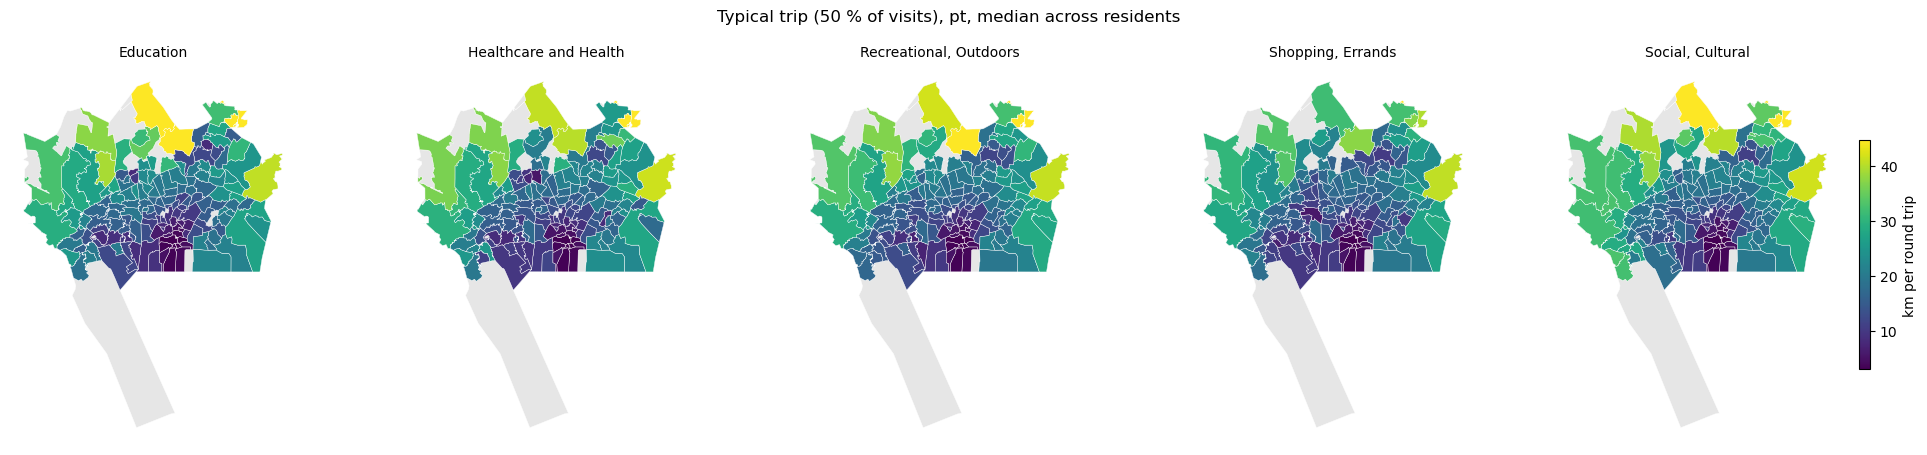

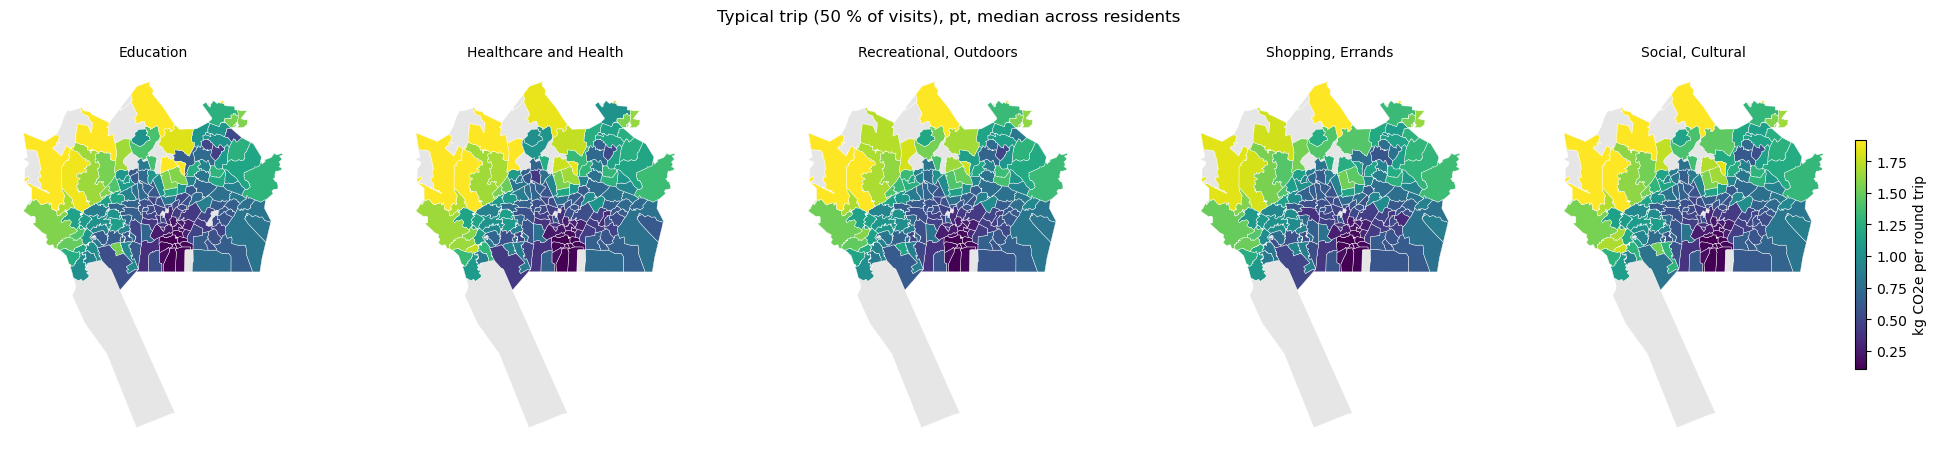

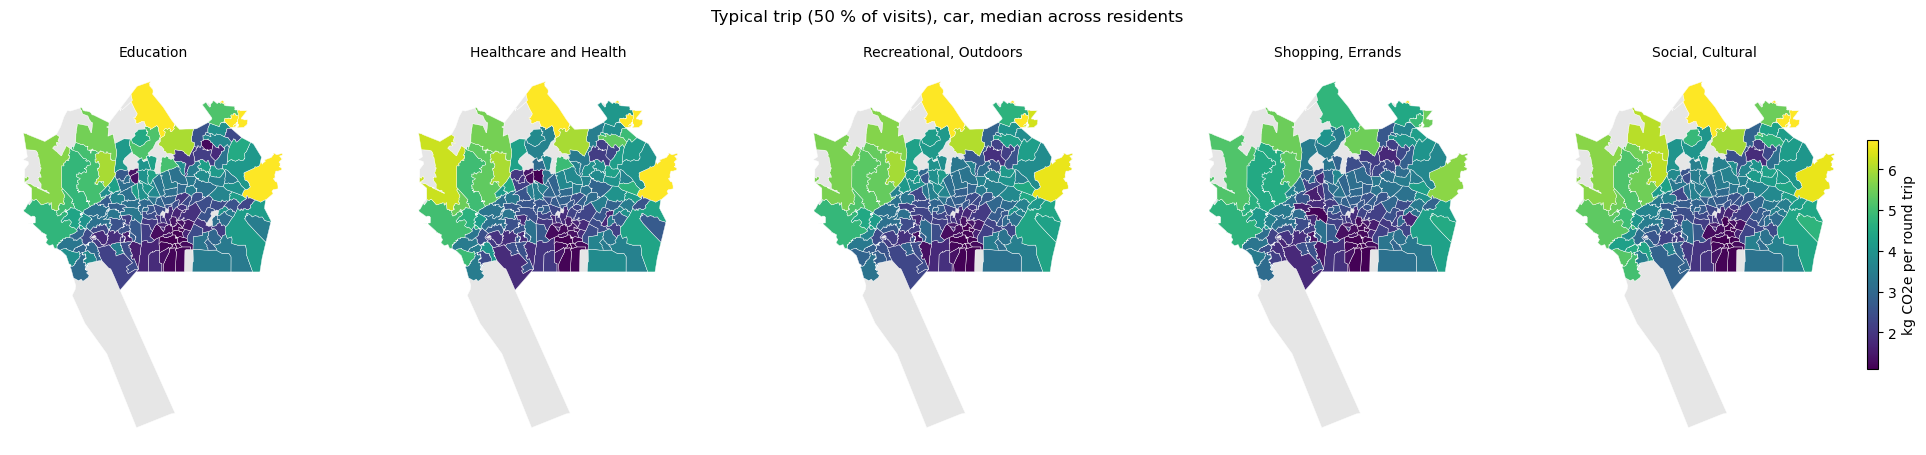

In [13]:
CATEGORY_COLOURS = dict(zip(CATEGORIES, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))


def plot_maps(mode, currency, threshold=50):
    label, scale = UNITS[currency]
    table = postal_table(mode, currency, threshold, scale=scale)
    shapes = postal.merge(table, left_on="Nimi", right_index=True, how="left")
    limits = (np.nanpercentile(table.values, 2), np.nanpercentile(table.values, 98))
    figure, axes = plt.subplots(ncols=len(CATEGORIES), figsize=(4 * len(CATEGORIES), 4.6))
    for axis, category in zip(axes, CATEGORIES):
        postal.plot(ax=axis, facecolor="#e6e6e6", edgecolor="white", linewidth=0.3)
        shapes.plot(ax=axis, column=category, cmap="viridis", vmin=limits[0], vmax=limits[1],
                    edgecolor="white", linewidth=0.3,
                    legend=(category == CATEGORIES[-1]),
                    legend_kwds={"label": label, "shrink": 0.6})
        axis.set_title(category, fontsize=10)
        axis.set_axis_off()
    figure.suptitle(f"Typical trip ({threshold} % of visits), {mode}, median across residents", y=0.98)
    figure.tight_layout()


plot_maps("pt", "distance_m")
plot_maps("pt", "co2_g")
plot_maps("car", "co2_g")

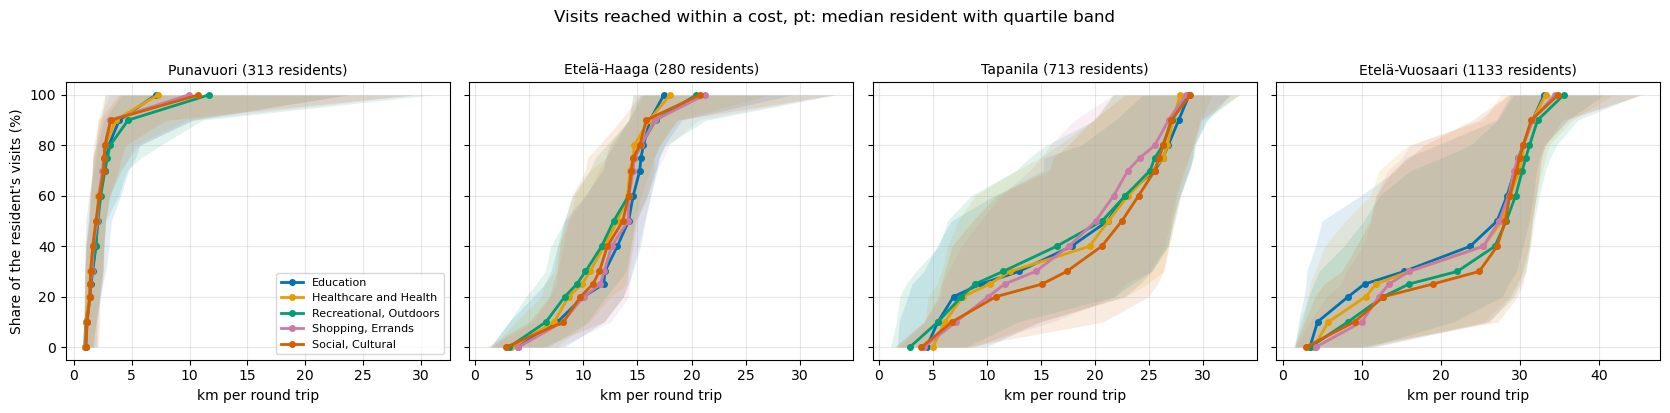

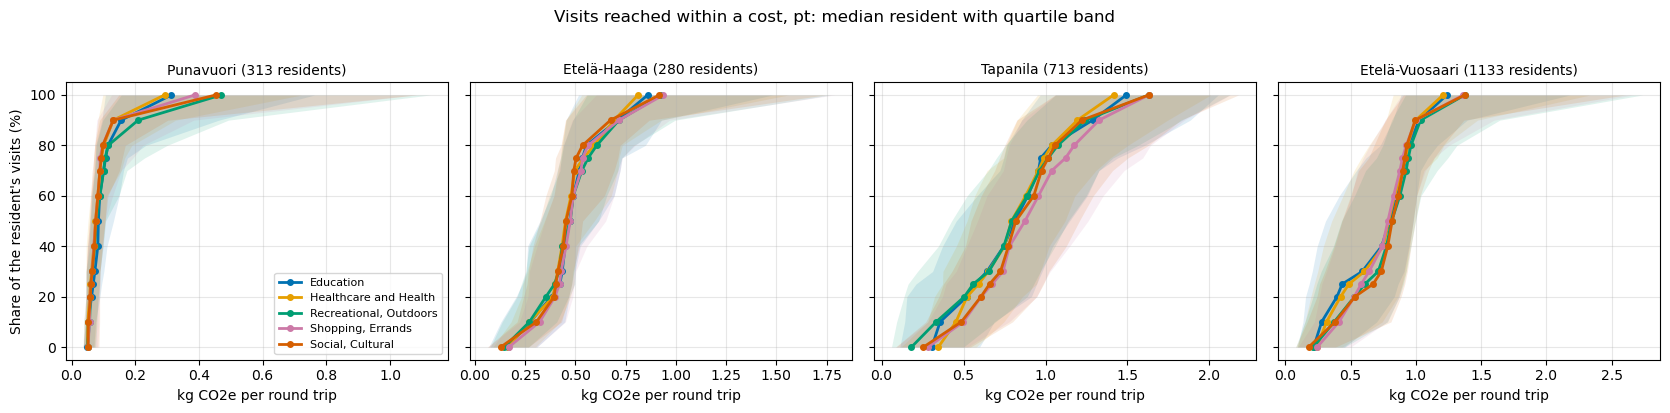

In [14]:
def plot_curves(names, mode, currency):
    '''Median across residents of the cost at each visit share, per category.'''
    label, scale = UNITS[currency]
    figure, axes = plt.subplots(ncols=len(names), figsize=(4.2 * len(names), 4), sharey=True)
    for axis, name in zip(np.atleast_1d(axes), names):
        rows = by_postal_code.loc[
            (by_postal_code["Nimi"] == name) & (by_postal_code["mode"] == mode)
            & (by_postal_code["currency"] == currency)
        ]
        for category in CATEGORIES:
            curve = rows.loc[rows["poi_type"] == category].sort_values("threshold")
            if curve.empty:
                continue
            axis.plot(curve["median"] * scale, curve["threshold"], marker="o", markersize=4,
                      linewidth=2, color=CATEGORY_COLOURS[category], label=category)
            axis.fill_betweenx(curve["threshold"], curve["p25"] * scale, curve["p75"] * scale,
                               color=CATEGORY_COLOURS[category], alpha=0.12, linewidth=0)
        users = rows.loc[rows["threshold"] == 50, "n_users"].max()
        axis.set_title(f"{name} ({users:.0f} residents)", fontsize=10)
        axis.set_xlabel(label)
        axis.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel("Share of the resident's visits (%)")
    np.atleast_1d(axes)[0].legend(fontsize=8, loc="lower right")
    figure.suptitle(f"Visits reached within a cost, {mode}: median resident with quartile band", y=1.02)
    figure.tight_layout()


EXAMPLES = ["Punavuori", "Etelä-Haaga", "Tapanila", "Etelä-Vuosaari"]
plot_curves(EXAMPLES, "pt", "distance_m")
plot_curves(EXAMPLES, "pt", "co2_g")

## Caveats

- A stay is a hexagon, not a POI: a hexagon with five shops and one school counts
  five times in the shopping curve and once in the education curve. Hexagons rich
  in one category therefore weigh more than the user's actual choice of place.
- Costs come from the paper's matrices and inherit their cut-offs (3,000 g for
  public transport and bicycle, 6,000 g for the car); longer trips are missing:
  about three home-to-stay pairs in ten have no public transport or car cost and
  four in ten no bicycle cost, so the upper deciles are truncated for some users.
- Bicycle distances are slope-weighted lengths, slightly above the ridden metres on
  hilly routes, and bicycle minutes follow from them at one assumed speed; both
  inherit the paper's 21 g/km conventions.
- The e-bike is not routed: it reuses the bicycle's slope-weighted distances, so its
  stay coverage and cut-off are the bicycle's, its minutes assume one speed and its
  grams one life-cycle factor; both are parameters above.
- Visits are counted as observed by the app over three months; users differ in
  how often their phone reports, so visit counts are a relative weight, not a
  trip rate.
- Postal codes with fewer than the minimum number of residents are flagged
  rather than dropped; the table and map cells filter them.